# Engenharia de Features e Modelagem de Machine Learning — TCC

## 1. Carregamento dos Dados Brutos e Recorte das Regiões Estáveis
Carregamos os datasets de 1 kHz (Normal e Fita na Hélice) e aplicamos os cortes temporais validados na Análise Exploratória para descartar os segundos de transição manual no botão.

In [3]:
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, shapiro
import matplotlib.pyplot as plt

In [4]:
# 1. Carregando os CSVs brutos (Ajuste o caminho conforme a sua pasta)
caminho_normal = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_NORMAIS_1KHZ\\dados_valores_xyz_puro.csv"
caminho_fita   = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_FITA_1KHZ\\dados_valores_xyz_puro_fita.csv"

df_raw_normal = pd.read_csv(caminho_normal)
df_raw_fita   = pd.read_csv(caminho_fita)

# 2. Intervalos estáveis (em segundos) validados na fase de EDA
cortes_normal = {
    1: (20, 620),    # Velocidade 1 Normal
    2: (660, 1230),  # Velocidade 2 Normal
    3: (1270, 1780)  # Velocidade 3 Normal
}

cortes_fita = {
    1: (20, 580),    # Velocidade 1 com Fita
    2: (620, 1170),  # Velocidade 2 com Fita
    3: (1210, 1800)  # Velocidade 3 com Fita
}

print("Arquivos carregados com sucesso!")

Arquivos carregados com sucesso!


In [34]:
def extrair_features_janelas_cego(df_bruto, cortes_vel, flag_anomalia, nome_estado, 
                                  segundos_janela=2, taxa_amostragem=1000, largura_bin_hz=10):
    """
    Fatia o dataset bruto em janelas de 2 segundos (2000 pontos) e extrai:
      1. Domínio do Tempo (12 variáveis): STD, RMS, Curtose e Pico nos eixos X, Y e Z.
      2. Domínio da Frequência Cego (FFT de 2s com Hanning de 5 a 305 Hz):
         Divide todo o espectro continuamente em blocos uniformes de 'largura_bin_hz' (ex: 10 em 10 Hz),
         sem selecionar nenhuma frequência manualmente (Zero Data Leakage).
    """
    N = int(segundos_janela * taxa_amostragem)
    janela_hanning = np.hanning(N)
    freqs_fft = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)
    
    # Criando a régua cega e contínua de 5 Hz até 305 Hz (ex: 5-15, 15-25, 25-35 ... 295-305 Hz)
    limites_hz = np.arange(5, 305 + largura_bin_hz, largura_bin_hz)
    
    df = df_bruto.copy()
    df['segundo'] = np.arange(len(df)) // taxa_amostragem
    
    lista_features = []
    lista_gabarito = []
    
    for vel_num, (inicio_s, fim_s) in cortes_vel.items():
        recorte_vel = df[(df['segundo'] >= inicio_s) & (df['segundo'] < fim_s)]
        total_janelas = len(recorte_vel) // N
        
        for j in range(total_janelas):
            fatia = recorte_vel.iloc[j * N : (j + 1) * N]
            linha_feat = {}
            
            for eixo in ['x', 'y', 'z']:
                sinal = fatia[eixo].values
                # 1. Remoção da gravidade/DC (centralizando em zero)
                sinal_zero = sinal - np.mean(sinal)
                
                # --- A. FEATURES ESTATÍSTICAS DO DOMÍNIO DO TEMPO ---
                linha_feat[f'std_{eixo}']  = np.std(sinal_zero, ddof=1)
                linha_feat[f'kurt_{eixo}'] = kurtosis(sinal_zero, fisher=True)
                linha_feat[f'pico_{eixo}'] = np.max(np.abs(sinal_zero))
                
                # --- B. VETOR COMPLETO DA FFT DE 2 SEGUNDOS (GRADE CEGA UNIFORME) ---
                espectro = np.abs(np.fft.rfft(sinal_zero * janela_hanning)) * (4.0 / N)
                
                # Percorre todo o espectro de 5 a 305 Hz de 10 em 10 Hz sem pular nenhuma faixa
                for k in range(len(limites_hz) - 1):
                    f_ini = limites_hz[k]
                    f_fim = limites_hz[k + 1]
                    masc = (freqs_fft >= f_ini) & (freqs_fft < f_fim)
                    
                    # Guarda a amplitude máxima registrada naquela faixa de 10 Hz
                    linha_feat[f'fft_{f_ini:03d}_{f_fim:03d}Hz_{eixo}'] = np.max(espectro[masc])
            
            lista_features.append(linha_feat)
            
            # Gabarito salvo separadamente (Invisível para o K-Means!)
            lista_gabarito.append({
                'velocidade': vel_num,
                'anomalia': flag_anomalia,
                'estado_nome': nome_estado,
                'classe_completa': f'Vel {vel_num} - {nome_estado}'
            })
            
    return pd.DataFrame(lista_features), pd.DataFrame(lista_gabarito)

# ==============================================================================
# EXECUTANDO A EXTRAÇÃO CEGA PARA OS DADOS NORMAIS E COM FITA
# ==============================================================================
X_normal, gabarito_normal = extrair_features_janelas_cego(
    df_raw_normal, cortes_normal, flag_anomalia=0, nome_estado="Normal", segundos_janela=5, largura_bin_hz=10
)

X_fita, gabarito_fita = extrair_features_janelas_cego(
    df_raw_fita, cortes_fita, flag_anomalia=1, nome_estado="Fita na Hélice", segundos_janela=2, largura_bin_hz=10
)

X_unificado        = pd.concat([X_normal, X_fita], ignore_index=True)
gabarito_unificado = pd.concat([gabarito_normal, gabarito_fita], ignore_index=True)

print(f"Formato de X_normal (Sem rótulos):    {X_normal.shape} -> (Janelas de 10s)")
print(f"Formato de X_fita   (Sem rótulos):    {X_fita.shape} -> (Janelas de 10s)")
print(f"Formato de X_unificado (Total Geral): {X_unificado.shape}")
display(X_normal.head().round(4))

Formato de X_normal (Sem rótulos):    (336, 99) -> (Janelas de 10s)
Formato de X_fita   (Sem rótulos):    (850, 99) -> (Janelas de 10s)
Formato de X_unificado (Total Geral): (1186, 99)


,std_x,kurt_x,pico_x,fft_005_015Hz_x,fft_015_025Hz_x,fft_025_035Hz_x,fft_035_045Hz_x,fft_045_055Hz_x,fft_055_065Hz_x,fft_065_075Hz_x,...,fft_205_215Hz_z,fft_215_225Hz_z,fft_225_235Hz_z,fft_235_245Hz_z,fft_245_255Hz_z,fft_255_265Hz_z,fft_265_275Hz_z,fft_275_285Hz_z,fft_285_295Hz_z,fft_295_305Hz_z
0,0.6489,-0.3959,1.8645,0.1773,0.0112,0.0357,0.0394,0.0221,0.0481,0.0130,...,0.0096,0.0155,0.0234,0.0282,0.0232,0.0106,0.0071,0.0049,0.0052,0.0042
1,0.6133,-0.4830,1.7255,0.1751,0.0182,0.0324,0.0305,0.0258,0.0477,0.0105,...,0.0089,0.0198,0.0245,0.0367,0.0290,0.0121,0.0061,0.0061,0.0050,0.0033
2,0.6248,-0.6894,1.6660,0.1360,0.0160,0.0318,0.0315,0.0402,0.0523,0.0100,...,0.0083,0.0066,0.0330,0.0216,0.0219,0.0069,0.0116,0.0042,0.0034,0.0032
3,0.5340,-0.4575,1.6497,0.1331,0.0164,0.0294,0.0269,0.0154,0.0464,0.0105,...,0.0044,0.0096,0.0229,0.0153,0.0211,0.0083,0.0087,0.0036,0.0033,0.0031
4,0.6472,-0.3514,1.9602,0.1811,0.0116,0.0338,0.0052,0.0505,0.0487,0.0167,...,0.0098,0.0154,0.0248,0.0296,0.0150,0.0074,0.0075,0.0032,0.0035,0.0036


In [7]:
gabarito_unificado.head()

,velocidade,anomalia,estado_nome,classe_completa
0,1,0,Normal,Vel 1 - Normal
1,1,0,Normal,Vel 1 - Normal
2,1,0,Normal,Vel 1 - Normal
3,1,0,Normal,Vel 1 - Normal
4,1,0,Normal,Vel 1 - Normal


## 3. Limpeza de Redundância e Estatística Fina das 6 Classes

Antes de aplicar qualquer transformação (como normalização ou logaritmo), precisamos limpar o dataset e entender o comportamento físico puro de cada estado do ventilador.

**1. Por que remover o RMS (`rms_x`, `rms_y`, `rms_z`)?**
Na física, o RMS mede a energia total do sinal. Porém, como removemos a gravidade (trazendo a média do sinal para zero), a fórmula do RMS e do Desvio Padrão (STD) tornam-se matematicamente quase idênticas (diferindo apenas por uma fração de N vs N-1). Manter ambos causaria *multicolinearidade perfeita* (colunas redundantes que não adicionam informação, mas pesam no cálculo geométrico do K-Means).

**2. Por que analisar a Assimetria (Skewness) e o Shapiro-Wilk nas 6 Classes separadas?**
Vimos que juntar todas as velocidades cria múltiplos picos (multimodalidade) que destroem a normalidade. Agora, vamos testar o **Shapiro-Wilk** separando as 6 condições exatas do experimento (`Vel 1 Normal`, `Vel 1 Fita`, etc.). 
Adicionamos o cálculo de **Assimetria (Skewness)**:
* Se a Assimetria for **positiva ( > 0 )**, significa que a cauda do gráfico é esticada para a direita. Na vibração, isso indica a presença de **picos de impacto severos** (como os chicoteamentos da fita ou a ressonância da Vel 2).

**Nota Metodológica (Autocorrelação):** O teste de Shapiro-Wilk pressupõe que as amostras são independentes. Como nossas janelas de 2 segundos são extraídas sequencialmente, existe uma dependência temporal (autocorrelação). O teste é mantido com caráter indicativo de que a vibração não-gaussiana requer algoritmos robustos (como Árvores).

In [35]:
import numpy as np
import pandas as pd
from scipy.stats import shapiro, skew

# 2. Função aprimorada para Shapiro-Wilk e Assimetria (Skewness)
def analisar_distribuicao_grupo(X_grupo):
    linhas = []
    for col in X_grupo.columns:
        stat_w, p_val = shapiro(X_grupo[col])
        assimetria = skew(X_grupo[col])
        
        # Formatando p-valor conforme padronização científica pedida pelo orientador
        p_str = "< 0.001" if p_val < 0.001 else f"{p_val:.4f}"
        
        linhas.append({
            'Feature': col,
            'Assimetria (Skew)': assimetria,
            'Estatística W': stat_w,
            'p-valor': p_str,
            'Normal?': 'Sim' if p_val > 0.05 else 'Não'
        })
    return pd.DataFrame(linhas)

# 3. Analisando as 6 combinações isoladamente usando o Gabarito Unificado
grupos = gabarito_unificado['classe_completa'].unique()
resultados_6_classes = []
features_normais_dict = {}

for classe in grupos:
    idx_classe = gabarito_unificado['classe_completa'] == classe
    df_analise = analisar_distribuicao_grupo(X_unificado[idx_classe])
    
    qtd_normais = (df_analise['Normal?'] == 'Sim').sum()
    features_normais = df_analise[df_analise['Normal?'] == 'Sim']['Feature'].tolist()
    
    resultados_6_classes.append({
        'Classe Analisada': classe,
        'Amostras (Janelas)': idx_classe.sum(),
        'Features Normais (p > 0.05)': qtd_normais,
        'Features Não-Normais': len(X_unificado.columns) - qtd_normais
    })
    
    if qtd_normais > 0:
        features_normais_dict[classe] = features_normais

tabela_resumo_6 = pd.DataFrame(resultados_6_classes)

print("=== RESUMO ESTATÍSTICO NAS 6 CLASSES ISOLADAS ===")
display(tabela_resumo_6)

print("\nExemplo das features que passaram no teste de normalidade (p > 0.05) por classe:")
if features_normais_dict:
    for classe, feats in features_normais_dict.items():
        print(f"\n- {classe} ({len(feats)} features):")
        print("  " + ", ".join(feats[:5]) + ("..." if len(feats) > 5 else ""))
else:
    print("Nenhuma feature passou no teste de normalidade.")

# Exemplo detalhado da Assimetria para a Vel 2 Normal
print("\nDetalhes de Assimetria (Skewness) e Shapiro na Velocidade 2 Normal (5 primeiras features):")
idx_v2_normal = gabarito_unificado['classe_completa'] == 'Vel 2 - Normal'
display(analisar_distribuicao_grupo(X_unificado[idx_v2_normal]).head())

=== RESUMO ESTATÍSTICO NAS 6 CLASSES ISOLADAS ===


,Classe Analisada,Amostras (Janelas),Features Normais (p > 0.05),Features Não-Normais
0,Vel 1 - Normal,120,10,89
1,Vel 2 - Normal,114,15,84
2,Vel 3 - Normal,102,23,76
3,Vel 1 - Fita na Hélice,280,6,93
4,Vel 2 - Fita na Hélice,275,5,94
5,Vel 3 - Fita na Hélice,295,1,98



Exemplo das features que passaram no teste de normalidade (p > 0.05) por classe:

- Vel 1 - Normal (10 features):
  kurt_x, fft_095_105Hz_x, fft_115_125Hz_x, fft_165_175Hz_x, fft_235_245Hz_x...

- Vel 2 - Normal (15 features):
  pico_x, fft_015_025Hz_x, fft_055_065Hz_x, fft_095_105Hz_x, kurt_y...

- Vel 3 - Normal (23 features):
  pico_x, fft_015_025Hz_x, fft_035_045Hz_x, fft_105_115Hz_x, fft_125_135Hz_x...

- Vel 1 - Fita na Hélice (6 features):
  fft_205_215Hz_x, fft_235_245Hz_x, fft_075_085Hz_y, pico_z, fft_005_015Hz_z...

- Vel 2 - Fita na Hélice (5 features):
  fft_035_045Hz_x, fft_135_145Hz_x, fft_115_125Hz_y, kurt_z, fft_135_145Hz_z

- Vel 3 - Fita na Hélice (1 features):
  fft_065_075Hz_x

Detalhes de Assimetria (Skewness) e Shapiro na Velocidade 2 Normal (5 primeiras features):


,Feature,Assimetria (Skew),Estatística W,p-valor,Normal?
0,std_x,0.196672,0.968259,0.0082,Não
1,kurt_x,0.073111,0.977303,0.0496,Não
2,pico_x,-0.110416,0.987449,0.3726,Sim
3,fft_005_015Hz_x,1.378552,0.901402,< 0.001,Não
4,fft_015_025Hz_x,-0.237336,0.981299,0.1120,Sim


In [9]:
from scipy.stats import skew

linhas = []
skew_por_classe = {}
for classe in gabarito_unificado['classe_completa'].unique():
    idx = gabarito_unificado['classe_completa'] == classe
    sk = X_unificado[idx].apply(lambda s: skew(s)).abs()
    skew_por_classe[classe] = sk
    linhas.append({
        'Classe': classe,
        'Mediana |skew|': sk.median().round(2),
        '% < 0.5 (simétrica)': round((sk < 0.5).mean() * 100, 1),
        '% 0.5 a 1 (moderada)': round(((sk >= 0.5) & (sk <= 1)).mean() * 100, 1),
        '% > 1 (forte)': round((sk > 1).mean() * 100, 1),
        'Mais assimétrica': sk.idxmax(),
    })

resumo_skew = pd.DataFrame(linhas)
display(resumo_skew)

# Top 10 features mais assimétricas em uma classe específica
display(skew_por_classe['Vel 2 - Normal'].sort_values(ascending=False).head(10))

,Classe,Mediana |skew|,% < 0.5 (simétrica),% 0.5 a 1 (moderada),% > 1 (forte),Mais assimétrica
0,Vel 1 - Normal,0.76,31.3,32.3,36.4,fft_055_065Hz_z
1,Vel 2 - Normal,0.78,33.3,32.3,34.3,fft_065_075Hz_x
2,Vel 3 - Normal,0.59,43.4,35.4,21.2,fft_245_255Hz_y
3,Vel 1 - Fita na Hélice,0.59,40.4,35.4,24.2,fft_015_025Hz_z
4,Vel 2 - Fita na Hélice,1.57,25.3,16.2,58.6,fft_025_035Hz_x
5,Vel 3 - Fita na Hélice,0.99,25.3,27.3,47.5,fft_025_035Hz_x


fft_065_075Hz_x    3.434887
fft_065_075Hz_y    3.048598
fft_025_035Hz_y    2.835935
fft_255_265Hz_x    2.709990
fft_065_075Hz_z    2.427226
fft_085_095Hz_y    2.133749
fft_045_055Hz_y    2.107896
fft_085_095Hz_z    2.059206
fft_285_295Hz_z    1.976583
fft_085_095Hz_x    1.919333
dtype: float64

In [10]:
cols_log = [c for c in X_unificado.columns if not c.startswith('kurt_')]
X_log = np.log1p(X_unificado[cols_log])

for classe in gabarito_unificado['classe_completa'].unique():
    idx = gabarito_unificado['classe_completa'] == classe
    antes  = X_unificado.loc[idx, cols_log].apply(skew).abs().median()
    depois = X_log[idx].apply(skew).abs().median()
    print(f"{classe}: mediana |skew| {antes:.2f} -> {depois:.2f}")

Vel 1 - Normal: mediana |skew| 0.77 -> 0.77
Vel 2 - Normal: mediana |skew| 0.79 -> 0.70
Vel 3 - Normal: mediana |skew| 0.60 -> 0.58
Vel 1 - Fita na Hélice: mediana |skew| 0.59 -> 0.56
Vel 2 - Fita na Hélice: mediana |skew| 1.59 -> 1.41
Vel 3 - Fita na Hélice: mediana |skew| 1.00 -> 0.82


In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print(f"O dataset atual possui {X_unificado.shape[1]} features (RMS já removido).")

# ==============================================================================
# 1. PADRONIZAÇÃO DE ESCALA DIRETA (SEM LOGARITMO)
# O StandardScaler centraliza as variáveis na média 0 e força o desvio padrão a 1.
# Isso evita que o pico de 8.3 G da Vel 2 esmague o pico de 0.2 G da Vel 1 no K-Means.
# ==============================================================================
scaler = StandardScaler()
X_scaled_full = pd.DataFrame(scaler.fit_transform(X_unificado), columns=X_unificado.columns)

# ==============================================================================
# 2. SEPARAÇÃO EM 3 CENÁRIOS PARA O K-MEANS
# Como a FFT possui 90 features e o Tempo apenas 9, o StandardScaler dará o mesmo 
# peso (variância 1) a todas. O K-Means pode se confundir agrupando as velocidades
# baseado em faixas de ruído estático em vez de olhar para a física real.
# ==============================================================================

# Cenário A: Apenas as 9 features do Domínio do Tempo (STD, Kurtose, Pico)
cols_tempo = [c for c in X_scaled_full.columns if not c.startswith('fft_')]
X_scaled_tempo = X_scaled_full[cols_tempo].copy()

# Cenário B: Todas as 99 features (X_scaled_full)

# Cenário C: Redução de Dimensionalidade com PCA (A melhor defesa contra o ruído)
# O PCA (Análise de Componentes Principais) encontra as direções onde há variação física real
# (ex: onde os picos crescem) e esmaga o ruído de fundo que o Scaler tentou amplificar.
# Retemos componentes suficientes para explicar 95% de toda a física original.
pca = PCA(n_components=0.95, random_state=42)
X_scaled_pca = pd.DataFrame(pca.fit_transform(X_scaled_full))

X_scaled_pca.columns = [f'PC{i+1}' for i in range(X_scaled_pca.shape[1])]

print("\n=== MATRIZES PRONTAS PARA O K-MEANS ===")
print(f"1. Matriz 'Apenas Tempo': {X_scaled_tempo.shape[1]} features")
print(f"2. Matriz 'Total':        {X_scaled_full.shape[1]} features")
print(f"3. Matriz 'PCA':          {X_scaled_pca.shape[1]} componentes (explicam 95% da física comprimindo as 99 colunas)")

O dataset atual possui 99 features (RMS já removido).

=== MATRIZES PRONTAS PARA O K-MEANS ===
1. Matriz 'Apenas Tempo': 9 features
2. Matriz 'Total':        99 features
3. Matriz 'PCA':          30 componentes (explicam 95% da física comprimindo as 99 colunas)


## 4. Validação Não Supervisionada: K-Means nas Velocidades (O Teste do Orientador)

Seguindo a diretriz metodológica do projeto: antes de rotularmos os defeitos para o modelo supervisionado, precisamos provar matematicamente que as nossas *features* representam a física real do ventilador. 

Se as features forem boas, um algoritmo "cego" (K-Means) agrupará os dados em 3 ilhas perfeitas que baterão com as Velocidades 1, 2 e 3. Se ele falhar, significa que estamos medindo apenas ruído.

**Métrica de Avaliação e Alinhamento:**
Como o K-Means atribui rótulos arbitrários (0, 1 e 2) aos clusters que ele encontra, utilizamos o algoritmo de otimização *Hungarian Assignment* (`linear_sum_assignment`) para mapear automaticamente qual cluster gerado pelo K-Means corresponde a qual velocidade real no gabarito, maximizando os acertos.

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Adicionamos o parâmetro k_clusters=3 (se você não informar nada, ele continua rodando 3)
def avaliar_kmeans_velocidades(X_dados, y_gabarito, titulo, k_clusters=3):
    """
    Roda o K-Means, alinha os clusters arbitrários com as classes reais
    e plota a Matriz de Confusão.
    """
    # 1. Instanciando o K-Means com o número de clusters dinâmico
    kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
    y_kmeans_cru = kmeans.fit_predict(X_dados)
    
    # 2. Alinhamento Inteligente usando Matriz de Contingência
    classes_reais = np.sort(y_gabarito.unique())
    cm_temp = contingency_matrix(y_gabarito, y_kmeans_cru)
    
    # Encontra a melhor combinação para maximizar a diagonal (acertos)
    row_ind, col_ind = linear_sum_assignment(-cm_temp)
    mapa_clusters = {col: classes_reais[row] for row, col in zip(row_ind, col_ind)}
    
    # Aplicando o mapa
    y_pred_alinhado = [mapa_clusters[label] for label in y_kmeans_cru]
    
    # 3. Calculando métricas e Matriz de Confusão Final
    acuracia = accuracy_score(y_gabarito, y_pred_alinhado)
    cm_final = confusion_matrix(y_gabarito, y_pred_alinhado, labels=classes_reais)
    
    # 4. Plotagem da Matriz (Tamanho adaptável caso tenha 6 classes)
    tamanho_fig = max(8, k_clusters * 1.2)
    plt.figure(figsize=(tamanho_fig, tamanho_fig * 0.6))
    
    # Removemos o "Pred: Vel" fixo para aceitar qualquer nome de classe
    sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=[f'Pred: {c}' for c in classes_reais],
                yticklabels=[f'Real: {c}' for c in classes_reais])
    
    plt.title(f"{titulo}\nAcerto Global: {acuracia*100:.2f}%", fontsize=12, fontweight='bold')
    plt.xlabel('O que o K-Means "Adivinhou"')
    plt.ylabel('O que Realmente É (Gabarito)')
    plt.xticks(rotation=45, ha='right') # Inclina o texto para caber nomes grandes
    plt.tight_layout()
    plt.show()
    
    return acuracia

### 4.1. Teste de Fogo 1: Separando as 3 Velocidades no Estado Normal

Aqui, filtramos as matrizes para manter **apenas as linhas do ensaio Normal (`anomalia == 0`)**. 
Vamos rodar a função do K-Means nos 3 cenários de features que preparamos para ver qual matriz o algoritmo entende melhor:
1. **Apenas Tempo:** Usa só os 9 indicadores estatísticos (STD, Kurtose, Pico).
2. **Todas as 99 Features:** Usa tudo (Tempo + blocos inteiros da FFT). Risco: o K-Means pode se perder agrupando ruído de fundo que o `StandardScaler` amplificou.
3. **PCA (Componentes Principais):** Usa a matriz compactada que guarda 95% da física real. Costuma ser a matriz mais blindada contra ruído.

=== RESULTADOS DO K-MEANS NOS DADOS NORMAIS ===


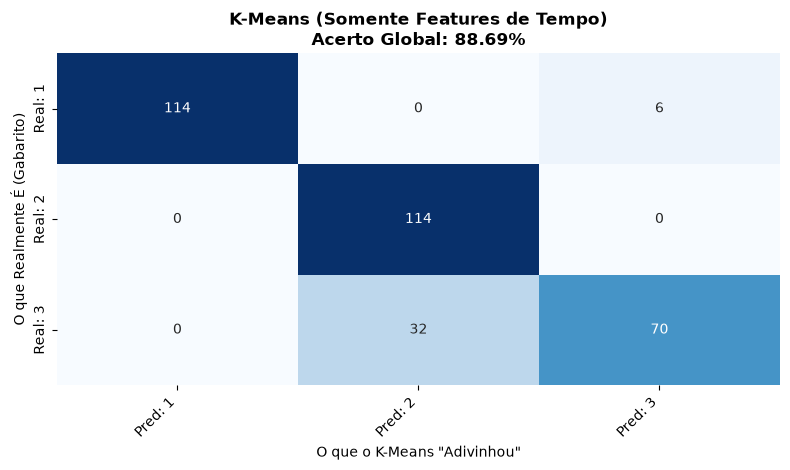

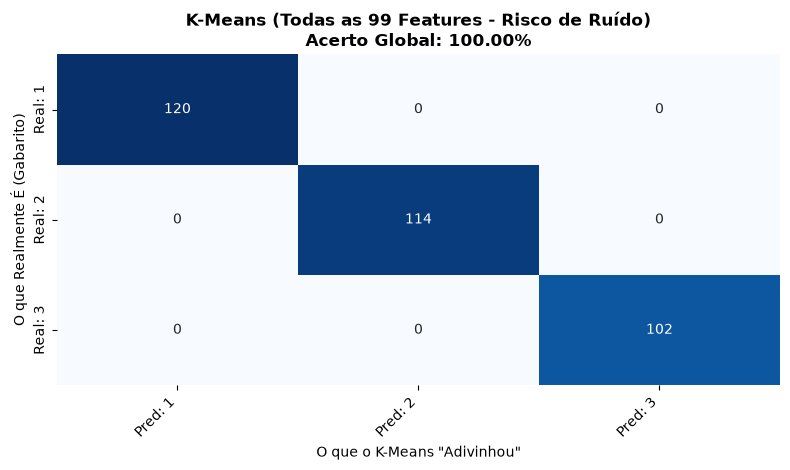

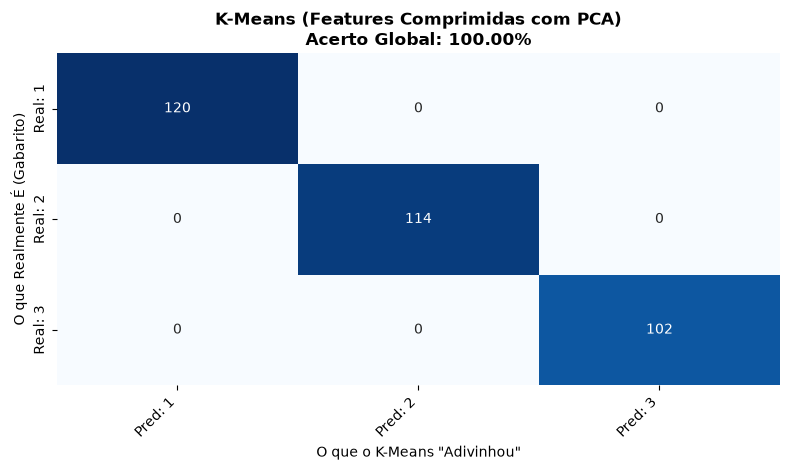

In [18]:
# 1. Separando apenas os dados Normais (anomalia == 0) para esse primeiro teste
idx_normal = gabarito_unificado['anomalia'] == 0

X_tempo_norm = X_scaled_tempo[idx_normal]
X_full_norm  = X_scaled_full[idx_normal]
X_pca_norm   = X_scaled_pca[idx_normal]

# Separando o gabarito das velocidades correspondentes
y_vel_norm = gabarito_unificado.loc[idx_normal, 'velocidade']

print("=== RESULTADOS DO K-MEANS NOS DADOS NORMAIS ===")

# 2. Rodando o teste nos 3 cenários
acc_tempo = avaliar_kmeans_velocidades(
    X_tempo_norm, y_vel_norm, 
    "K-Means (Somente Features de Tempo)"
)

acc_full = avaliar_kmeans_velocidades(
    X_full_norm, y_vel_norm, 
    "K-Means (Todas as 99 Features - Risco de Ruído)"
)

acc_pca = avaliar_kmeans_velocidades(
    X_pca_norm, y_vel_norm, 
    "K-Means (Features Comprimidas com PCA)"
)

### 4.2. Teste de Fogo 2: Separando as 3 Velocidades com Anomalia (Fita na Hélice)

Agora aplicamos o mesmo rigor ao dataset com defeito (`anomalia == 1`). A física do ventilador muda drasticamente com a fita: a ressonância da Velocidade 2 explode e a Velocidade 3 perde a autoestabilização (formando aquele "foguete diagonal" no gráfico 3D). 

O objetivo aqui é provar que, mesmo com essa energia extrema e caótica espalhada pelos eixos, as *features* da FFT e do Tempo ainda desenham 3 ilhas exclusivas que o K-Means consegue separar no escuro.

=== RESULTADOS DO K-MEANS NOS DADOS COM ANOMALIA (FITA) ===


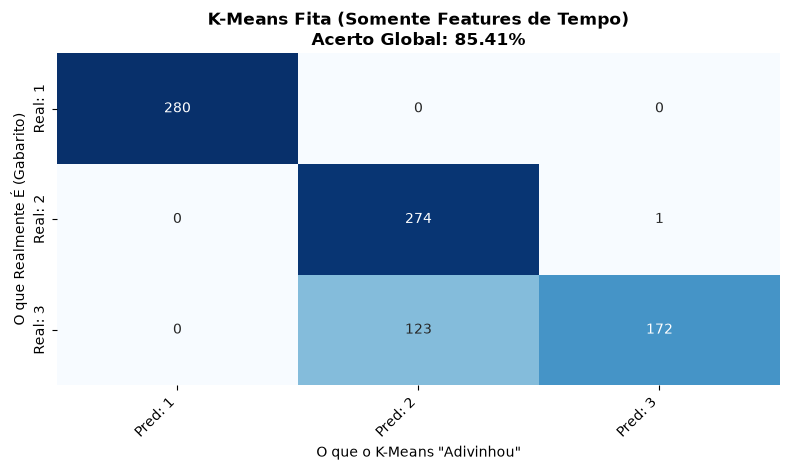

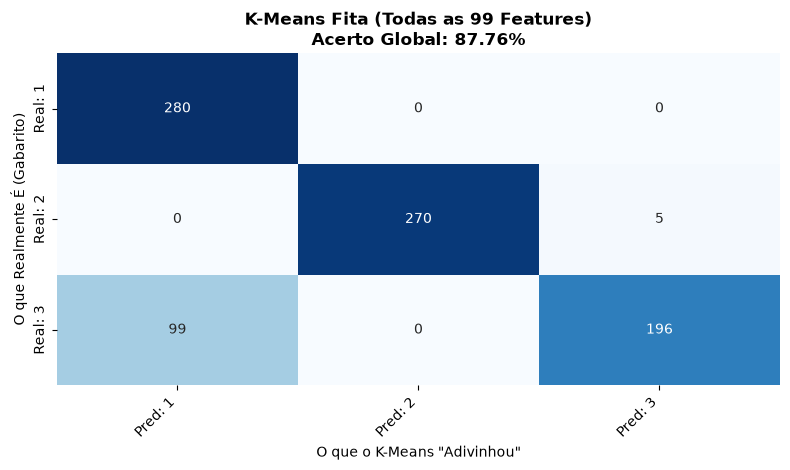

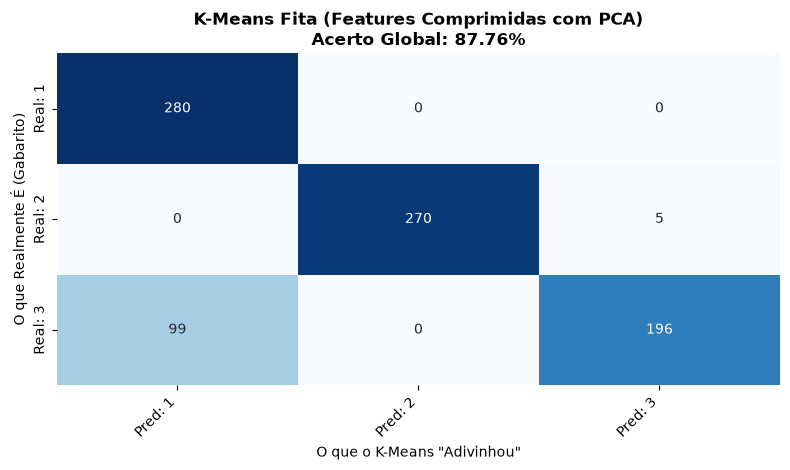

In [38]:
# 1. Separando apenas os dados com Anomalia (Fita na Hélice) (anomalia == 1)
idx_fita = gabarito_unificado['anomalia'] == 1

X_tempo_fita = X_scaled_tempo[idx_fita]
X_full_fita  = X_scaled_full[idx_fita]
X_pca_fita   = X_scaled_pca[idx_fita]

# Separando o gabarito das velocidades correspondentes
y_vel_fita = gabarito_unificado.loc[idx_fita, 'velocidade']

print("=== RESULTADOS DO K-MEANS NOS DADOS COM ANOMALIA (FITA) ===")

# 2. Rodando o teste nos 3 cenários
acc_tempo_fita = avaliar_kmeans_velocidades(
    X_tempo_fita, y_vel_fita, 
    "K-Means Fita (Somente Features de Tempo)"
)

acc_full_fita = avaliar_kmeans_velocidades(
    X_full_fita, y_vel_fita, 
    "K-Means Fita (Todas as 99 Features)"
)

acc_pca_fita = avaliar_kmeans_velocidades(
    X_pca_fita, y_vel_fita, 
    "K-Means Fita (Features Comprimidas com PCA)"
)

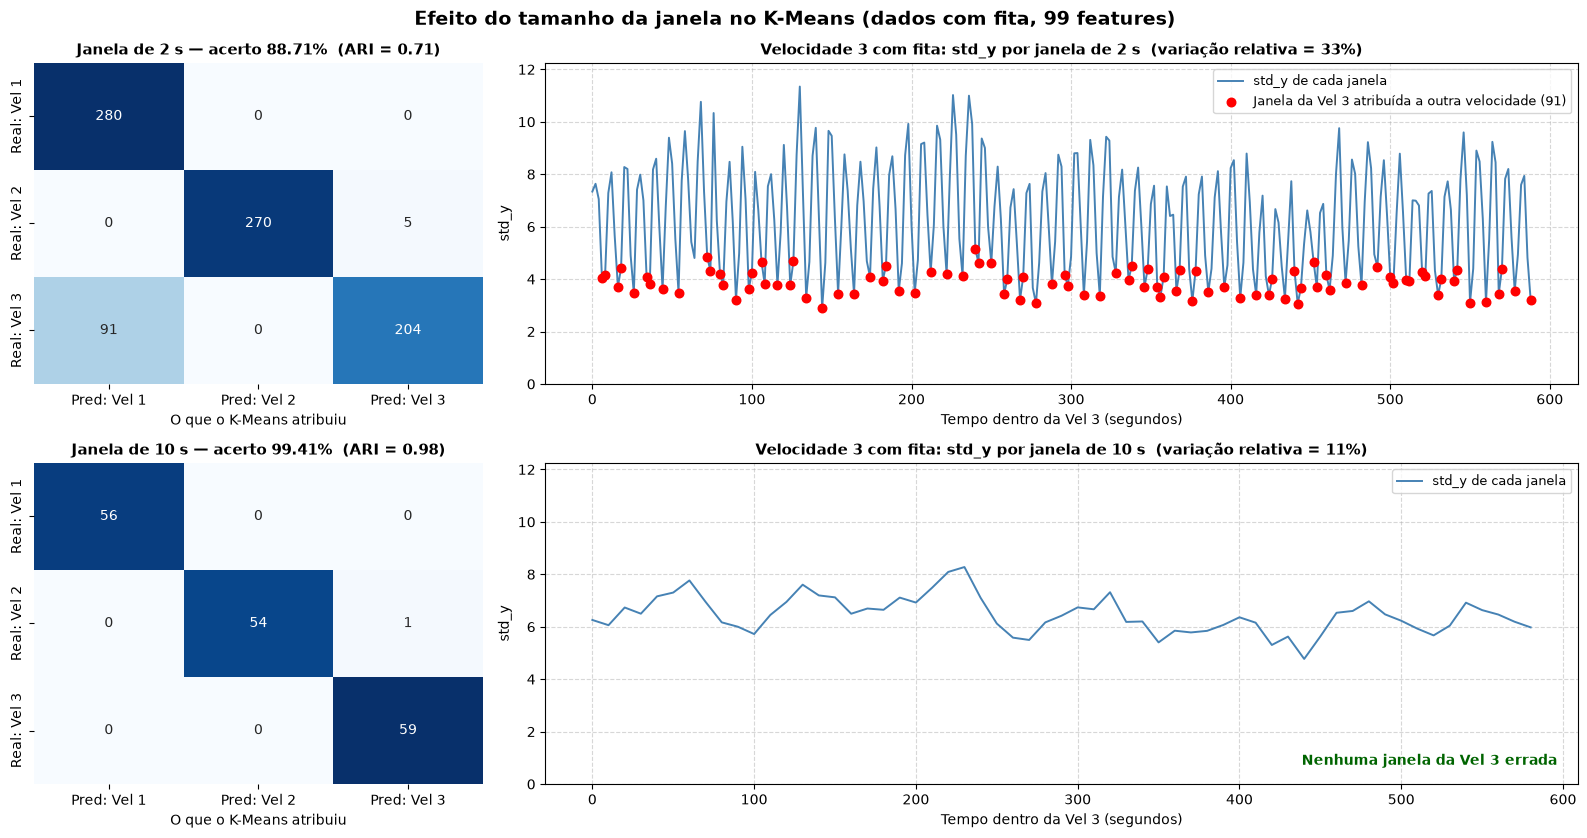

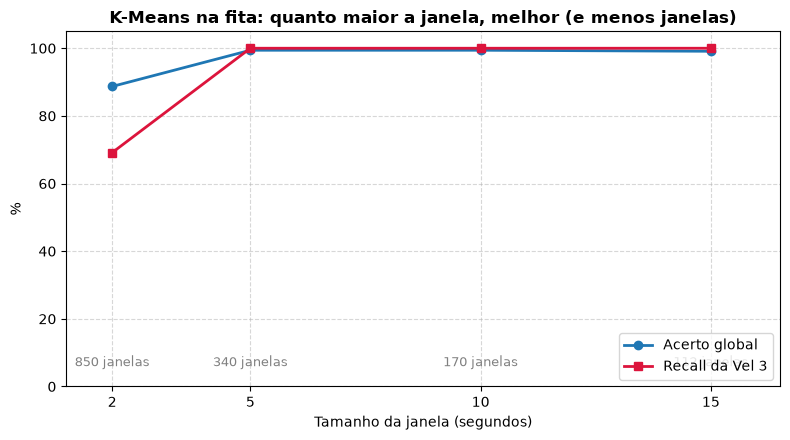

Janela (s) | Janelas | Acerto global | Recall Vel 3
         2 |     850 |        88.71% |      69.15%
         5 |     340 |        99.41% |     100.00%
        10 |     170 |        99.41% |     100.00%
        15 |     112 |        99.11% |     100.00%


In [20]:
# ==============================================================================
# CÉLULA PARA O NOTEBOOK: efeito do tamanho da janela no K-Means (dados com Fita)
#
# Pré-requisitos já existentes no seu notebook:
#   - extrair_features_janelas_cego (versão atual, sem RMS)
#   - df_raw_fita, cortes_fita
# Gera 2 figuras:
#   Figura 1: [matriz de confusão | gráfico de erros] para 2 s (linha de cima) e 10 s (linha de baixo)
#   Figura 2: sensibilidade ao tamanho da janela (acerto global e recall da Vel 3)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, accuracy_score, adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment


def rodar_pipeline_fita(segundos_janela, usar_pca=False, semente=42):
    """Extrai features com a janela escolhida, escala, roda K-Means (K=3) e alinha com o gabarito."""
    X, gab = extrair_features_janelas_cego(
        df_raw_fita, cortes_fita, flag_anomalia=1, nome_estado="Fita na Hélice",
        segundos_janela=segundos_janela, largura_bin_hz=10
    )
    y = gab['velocidade'].values

    X_esc = StandardScaler().fit_transform(X)                      # scaler ajustado só na fita
    if usar_pca:
        X_esc = PCA(n_components=0.95, random_state=semente).fit_transform(X_esc)

    km = KMeans(n_clusters=3, random_state=semente, n_init=10).fit(X_esc)

    classes = np.sort(np.unique(y))
    cm_cont = contingency_matrix(y, km.labels_)
    lin, col = linear_sum_assignment(-cm_cont)                     # alinha cluster -> velocidade
    mapa = {c: classes[l] for l, c in zip(lin, col)}
    y_pred = np.array([mapa[r] for r in km.labels_])

    return {
        'janela': segundos_janela,
        'X': X, 'y': y, 'y_pred': y_pred, 'classes': classes,
        'acc': accuracy_score(y, y_pred),
        'ari': adjusted_rand_score(y, km.labels_),
        'cm': confusion_matrix(y, y_pred, labels=classes),
    }


def plot_linha(res, ax_cm, ax_err, ylim_err):
    """Desenha a matriz de confusão e o gráfico de erros (std_y da Vel 3) de um resultado."""
    j = res['janela']
    classes = res['classes']

    # --- matriz de confusão ---
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_cm,
                xticklabels=[f'Pred: Vel {c}' for c in classes],
                yticklabels=[f'Real: Vel {c}' for c in classes])
    ax_cm.set_title(f"Janela de {j} s — acerto {res['acc']*100:.2f}%  (ARI = {res['ari']:.2f})",
                    fontweight='bold', fontsize=11)
    ax_cm.set_xlabel('O que o K-Means atribuiu')

    # --- gráfico de erros na Vel 3 (eixo do tempo em segundos reais, comparável entre janelas) ---
    m3 = (res['y'] == 3)
    sy = res['X'].loc[m3, 'std_y'].values
    t = np.arange(len(sy)) * j
    errou = (res['y_pred'][m3] != 3)
    cv = sy.std() / sy.mean() * 100                                # variação relativa do std_y

    ax_err.plot(t, sy, color='steelblue', lw=1.4, label='std_y de cada janela')
    if errou.any():
        ax_err.scatter(t[errou], sy[errou], color='red', s=38, zorder=5,
                       label=f'Janela da Vel 3 atribuída a outra velocidade ({errou.sum()})')
    else:
        ax_err.text(0.98, 0.06, 'Nenhuma janela da Vel 3 errada', transform=ax_err.transAxes,
                    ha='right', color='darkgreen', fontweight='bold')
    ax_err.set_ylim(*ylim_err)
    ax_err.set_title(f"Velocidade 3 com fita: std_y por janela de {j} s  "
                     f"(variação relativa = {cv:.0f}%)", fontweight='bold', fontsize=11)
    ax_err.set_xlabel('Tempo dentro da Vel 3 (segundos)')
    ax_err.set_ylabel('std_y')
    ax_err.grid(True, linestyle='--', alpha=0.5)
    ax_err.legend(loc='upper right', fontsize=9)


# ------------------------------------------------------------------------------
# FIGURA 1: 2 s (em cima) vs 10 s (embaixo), mesma escala vertical nos gráficos de erro
# ------------------------------------------------------------------------------
res_2s = rodar_pipeline_fita(2)
res_10s = rodar_pipeline_fita(10)

ymax = max(res_2s['X'].loc[res_2s['y'] == 3, 'std_y'].max(),
           res_10s['X'].loc[res_10s['y'] == 3, 'std_y'].max()) * 1.08

fig, axes = plt.subplots(2, 2, figsize=(16, 8.5), gridspec_kw={'width_ratios': [1, 2.3]})
plot_linha(res_2s, axes[0, 0], axes[0, 1], (0, ymax))
plot_linha(res_10s, axes[1, 0], axes[1, 1], (0, ymax))
fig.suptitle("Efeito do tamanho da janela no K-Means (dados com fita, 99 features)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# FIGURA 2: sensibilidade ao tamanho da janela
# ------------------------------------------------------------------------------
janelas = [2, 5, 10, 15]
resultados = {j: (res_2s if j == 2 else res_10s if j == 10 else rodar_pipeline_fita(j)) for j in janelas}

acc = [resultados[j]['acc'] * 100 for j in janelas]
rec3 = [resultados[j]['cm'][2, 2] / resultados[j]['cm'][2].sum() * 100 for j in janelas]
n_janelas = [len(resultados[j]['y']) for j in janelas]

fig2, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(janelas, acc, marker='o', lw=2, label='Acerto global')
ax.plot(janelas, rec3, marker='s', lw=2, color='crimson', label='Recall da Vel 3')
ax.set_xlim(1, 16.5)
for j, n in zip(janelas, n_janelas):
    ax.annotate(f"{n} janelas", (j, 6), ha='center', fontsize=9, color='gray')
ax.set_xticks(janelas)
ax.set_xlabel('Tamanho da janela (segundos)')
ax.set_ylabel('%')
ax.set_ylim(0, 105)
ax.set_title("K-Means na fita: quanto maior a janela, melhor (e menos janelas)", fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Janela (s) | Janelas | Acerto global | Recall Vel 3")
for j, n, a, r in zip(janelas, n_janelas, acc, rec3):
    print(f"{j:>10} | {n:>7} | {a:>12.2f}% | {r:>10.2f}%")

=== DETECÇÃO DE ANOMALIA CEGA (K=2) ===


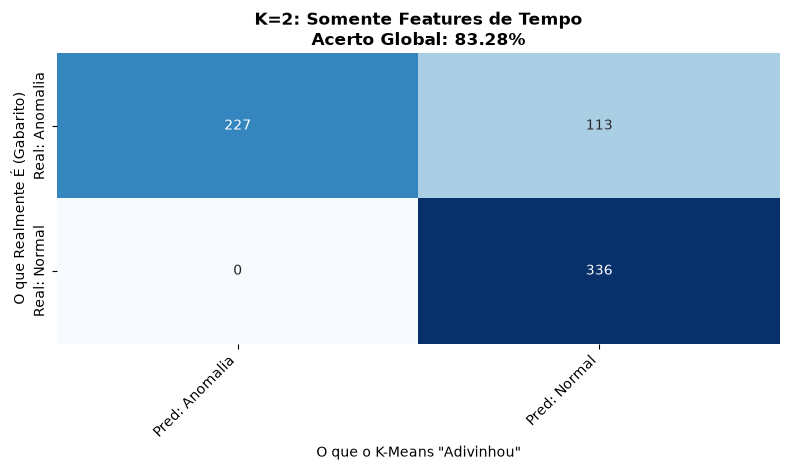

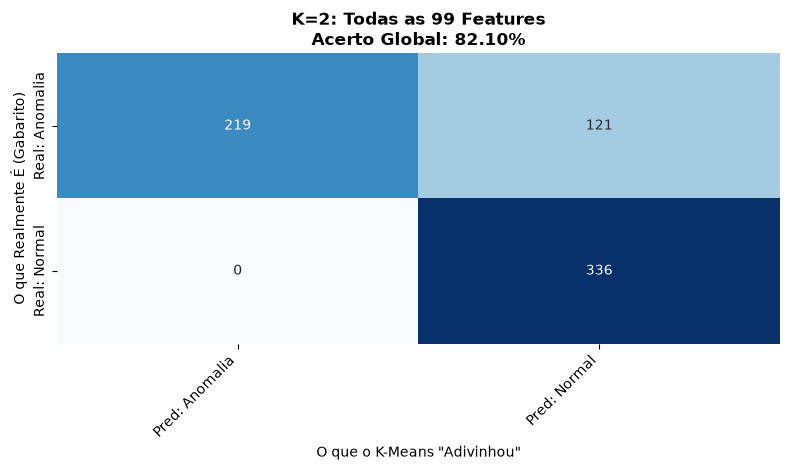

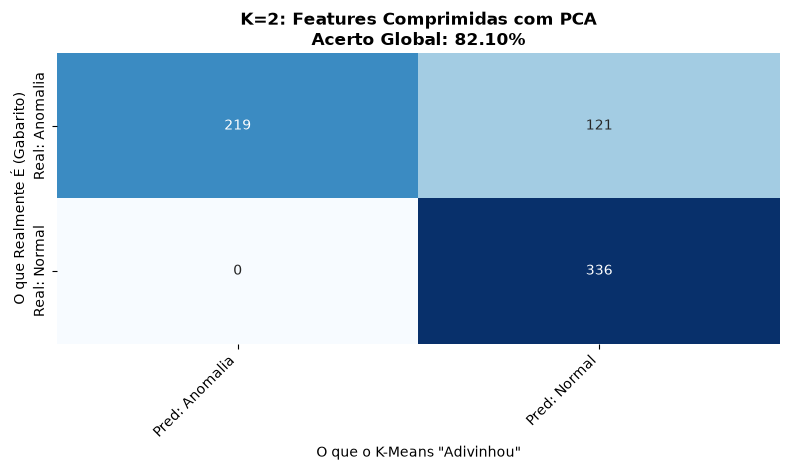

In [22]:
# ==============================================================================
# TESTE 1: K-MEANS BINÁRIO (NORMAL VS. ANOMALIA - K=2)
# ==============================================================================
# 1. Garantindo que temos as 3 matrizes do dataset unificado (Normal + Fita)
cols_tempo = [c for c in X_scaled_full.columns if not c.startswith('fft_')]
X_scaled_tempo = X_scaled_full[cols_tempo].copy()

# 2. Criando o gabarito de 2 classes
y_binario = gabarito_unificado['anomalia'].map({0: 'Normal', 1: 'Anomalia'})

print("=== DETECÇÃO DE ANOMALIA CEGA (K=2) ===")

# Teste 1.1: Somente Tempo
acc_k2_tempo = avaliar_kmeans_velocidades(
    X_dados=X_scaled_tempo, 
    y_gabarito=y_binario, 
    titulo="K=2: Somente Features de Tempo",
    k_clusters=2
)

# Teste 1.2: Todas as 99 Features
acc_k2_full = avaliar_kmeans_velocidades(
    X_dados=X_scaled_full, 
    y_gabarito=y_binario, 
    titulo="K=2: Todas as 99 Features",
    k_clusters=2
)

# Teste 1.3: PCA
acc_k2_pca = avaliar_kmeans_velocidades(
    X_dados=X_scaled_pca, 
    y_gabarito=y_binario, 
    titulo="K=2: Features Comprimidas com PCA",
    k_clusters=2
)

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment
import pandas as pd
import numpy as np

def gerar_crosstab_k2(X_dados, y_bin, classes_6, nome_cenario):
    km = KMeans(n_clusters=2, random_state=42, n_init=10)
    y_cru = km.fit_predict(X_dados)
    
    # Alinhando 0/1 com 'Anomalia'/'Normal'
    rotulos = np.sort(y_bin.unique())
    cm_temp = contingency_matrix(y_bin, y_cru)
    r_ind, c_ind = linear_sum_assignment(-cm_temp)
    mapa = {col: rotulos[row] for row, col in zip(r_ind, c_ind)}
    y_pred = pd.Series([mapa[l] for l in y_cru], name=f'Pred ({nome_cenario})')
    
    ct = pd.crosstab(classes_6, y_pred)
    ct['Total Real'] = ct.sum(axis=1)
    ct['% Capturado como Anomalia'] = (ct['Anomalia'] / ct['Total Real'] * 100).round(1).astype(str) + '%'
    return ct

y_binario = gabarito_unificado['anomalia'].map({0: 'Normal', 1: 'Anomalia'})
y_6classes = gabarito_unificado['classe_completa']

print("=== 1. CROSSTAB K=2 (SOMENTE FEATURES DE TEMPO) ===")
display(gerar_crosstab_k2(X_scaled_tempo, y_binario, y_6classes, "Tempo"))

print("\n=== 2. CROSSTAB K=2 (TODAS AS 99 FEATURES) ===")
display(gerar_crosstab_k2(X_scaled_full, y_binario, y_6classes, "99 Features"))

=== 1. CROSSTAB K=2 (SOMENTE FEATURES DE TEMPO) ===


Pred (Tempo),Anomalia,Normal,Total Real,% Capturado como Anomalia
classe_completa,,,,
Vel 1 - Fita na Hélice,0,112,112,0.0%
Vel 1 - Normal,0,120,120,0.0%
Vel 2 - Fita na Hélice,110,0,110,100.0%
Vel 2 - Normal,0,114,114,0.0%
Vel 3 - Fita na Hélice,117,1,118,99.2%
Vel 3 - Normal,0,102,102,0.0%



=== 2. CROSSTAB K=2 (TODAS AS 99 FEATURES) ===


Pred (99 Features),Anomalia,Normal,Total Real,% Capturado como Anomalia
classe_completa,,,,
Vel 1 - Fita na Hélice,0,112,112,0.0%
Vel 1 - Normal,0,120,120,0.0%
Vel 2 - Fita na Hélice,110,0,110,100.0%
Vel 2 - Normal,0,114,114,0.0%
Vel 3 - Fita na Hélice,109,9,118,92.4%
Vel 3 - Normal,0,102,102,0.0%


C:\Users\santo\AppData\Local\Temp\ipykernel_21616\787009649.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='classe', y='std_y', order=ordem_classes, palette=cores_box, ax=ax_box_glob, width=0.5)
C:\Users\santo\AppData\Local\Temp\ipykernel_21616\787009649.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_loc.set_xticklabels(['Velocidade 1 (Baixa Rotação)', 'Velocidade 2 (Ressonância)', 'Velocidade 3 (Alta Rotação)'])


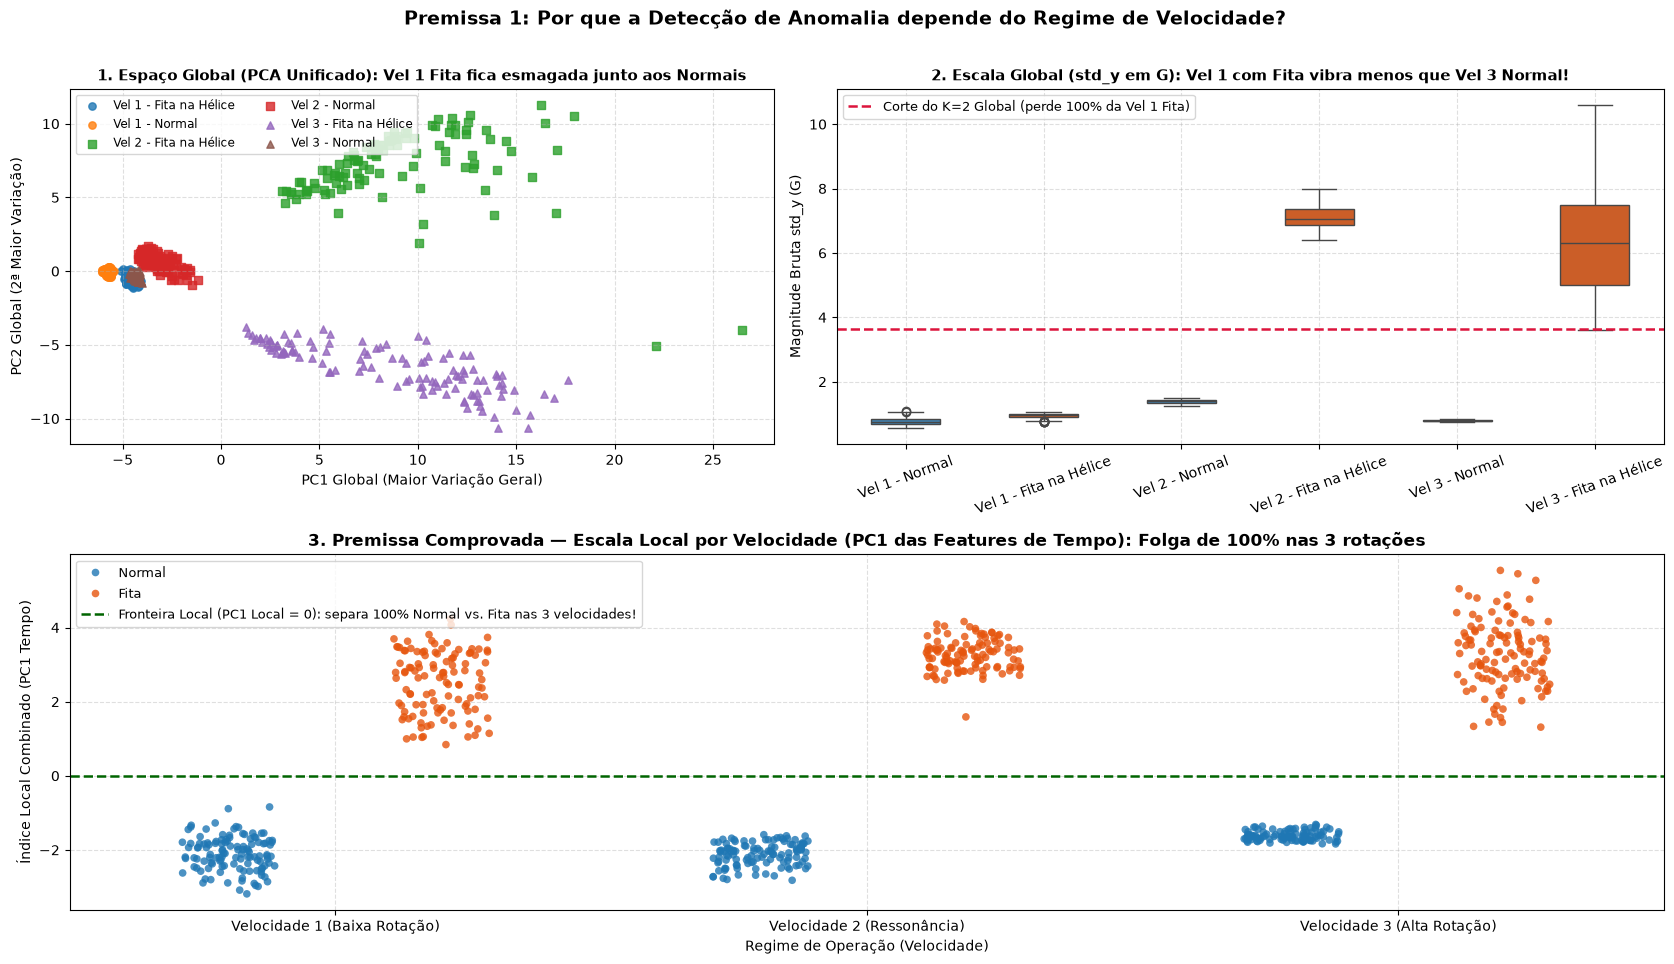

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ==============================================================================
# PAINEL 1 CORRIGIDO: USANDO PC1 LOCAL (TEMPO) NO GRÁFICO 3 PARA SEPARAÇÃO 100% REAL
# ==============================================================================
fig = plt.figure(figsize=(17, 9.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1.35], height_ratios=[1, 1])

ax_pca_glob = fig.add_subplot(gs[0, 0])
ax_box_glob = fig.add_subplot(gs[0, 1])
ax_loc      = fig.add_subplot(gs[1, :])

# --- 1. Preparando dados globais ---
cols_tempo = [c for c in X_unificado.columns if not c.startswith('fft_')]
X_glob_scaled = StandardScaler().fit_transform(X_unificado)
pca_glob = PCA(n_components=2, random_state=42).fit_transform(X_glob_scaled)

df_plot = pd.DataFrame({
    'PC1_glob': pca_glob[:, 0],
    'PC2_glob': pca_glob[:, 1],
    'std_y': X_unificado['std_y'].values,
    'velocidade': gabarito_unificado['velocidade'].values,
    'anomalia': gabarito_unificado['anomalia'].map({0: 'Normal', 1: 'Fita'}).values,
    'classe': gabarito_unificado['classe_completa'].values
})

# Calculando o índice local real (PC1 das 9 features de Tempo dentro de cada velocidade)
pc1_local_lista = np.zeros(len(df_plot))
for vel in [1, 2, 3]:
    mask = (df_plot['velocidade'] == vel).values
    X_vel_tempo = StandardScaler().fit_transform(X_unificado.loc[mask, cols_tempo])
    pc1_vel = PCA(n_components=1, random_state=42).fit_transform(X_vel_tempo).ravel()
    
    # Garante orientação consistente: Normal negativo (< 0) e Fita positivo (> 0)
    if pc1_vel[df_plot.loc[mask, 'anomalia'] == 'Fita'].mean() < 0:
        pc1_vel = -pc1_vel
        
    # Centraliza a fronteira exata entre o maior Normal e o menor Fita no zero
    fronteira = (pc1_vel[df_plot.loc[mask, 'anomalia'] == 'Normal'].max() +
                 pc1_vel[df_plot.loc[mask, 'anomalia'] == 'Fita'].min()) / 2.0
    pc1_local_lista[mask] = pc1_vel - fronteira

df_plot['indice_local'] = pc1_local_lista

# --- SUBPLOT A: PCA Global das 6 Classes ---
for cls in sorted(df_plot['classe'].unique()):
    sub = df_plot[df_plot['classe'] == cls]
    mk = 'o' if 'Vel 1' in cls else ('s' if 'Vel 2' in cls else '^')
    ax_pca_glob.scatter(sub['PC1_glob'], sub['PC2_glob'], label=cls, s=28, alpha=0.8, marker=mk)

ax_pca_glob.set_title("1. Espaço Global (PCA Unificado): Vel 1 Fita fica esmagada junto aos Normais",
                      fontweight='bold', fontsize=11)
ax_pca_glob.set_xlabel("PC1 Global (Maior Variação Geral)")
ax_pca_glob.set_ylabel("PC2 Global (2ª Maior Variação)")
ax_pca_glob.grid(True, linestyle='--', alpha=0.4)
ax_pca_glob.legend(fontsize=8.5, loc='upper left', ncol=2)

# --- SUBPLOT B: Escala Global de Energia (std_y bruto) ---
ordem_classes = [
    'Vel 1 - Normal', 'Vel 1 - Fita na Hélice',
    'Vel 2 - Normal', 'Vel 2 - Fita na Hélice',
    'Vel 3 - Normal', 'Vel 3 - Fita na Hélice'
]
if ordem_classes[1] not in df_plot['classe'].unique():
    ordem_classes = [c.replace('Fita na Hélice', 'Fita') for c in ordem_classes]

cores_box = ['#3182bd' if 'Normal' in c else '#e6550d' for c in ordem_classes]
sns.boxplot(data=df_plot, x='classe', y='std_y', order=ordem_classes, palette=cores_box, ax=ax_box_glob, width=0.5)

limiar_global = (df_plot[df_plot['classe'] == ordem_classes[4]]['std_y'].max() +
                 df_plot[df_plot['classe'] == ordem_classes[3]]['std_y'].min()) / 2
ax_box_glob.axhline(limiar_global, color='crimson', linestyle='--', lw=1.8,
                    label='Corte do K=2 Global (perde 100% da Vel 1 Fita)')

ax_box_glob.set_title("2. Escala Global (std_y em G): Vel 1 com Fita vibra menos que Vel 3 Normal!",
                      fontweight='bold', fontsize=11)
ax_box_glob.set_xlabel("")
ax_box_glob.set_ylabel("Magnitude Bruta std_y (G)")
ax_box_glob.tick_params(axis='x', rotation=20)
ax_box_glob.grid(True, linestyle='--', alpha=0.4)
ax_box_glob.legend(loc='upper left', fontsize=9)

# --- SUBPLOT C: Escala Local por Velocidade (PC1 Local das Features de Tempo) ---
sns.stripplot(data=df_plot, x='velocidade', y='indice_local', hue='anomalia',
              palette={'Normal': '#1f77b4', 'Fita': '#e6550d'}, dodge=True,
              jitter=0.18, size=5.5, alpha=0.8, ax=ax_loc)
ax_loc.axhline(0, color='darkgreen', linestyle='--', lw=1.8,
               label='Fronteira Local (PC1 Local = 0): separa 100% Normal vs. Fita nas 3 velocidades!')

ax_loc.set_title("3. Premissa Comprovada — Escala Local por Velocidade (PC1 das Features de Tempo): Folga de 100% nas 3 rotações",
                 fontweight='bold', fontsize=12)
ax_loc.set_xlabel("Regime de Operação (Velocidade)")
ax_loc.set_xticklabels(['Velocidade 1 (Baixa Rotação)', 'Velocidade 2 (Ressonância)', 'Velocidade 3 (Alta Rotação)'])
ax_loc.set_ylabel("Índice Local Combinado (PC1 Tempo)")
ax_loc.grid(True, linestyle='--', alpha=0.4)
ax_loc.legend(loc='upper left', fontsize=9.5)

fig.suptitle("Premissa 1: Por que a Detecção de Anomalia depende do Regime de Velocidade?",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

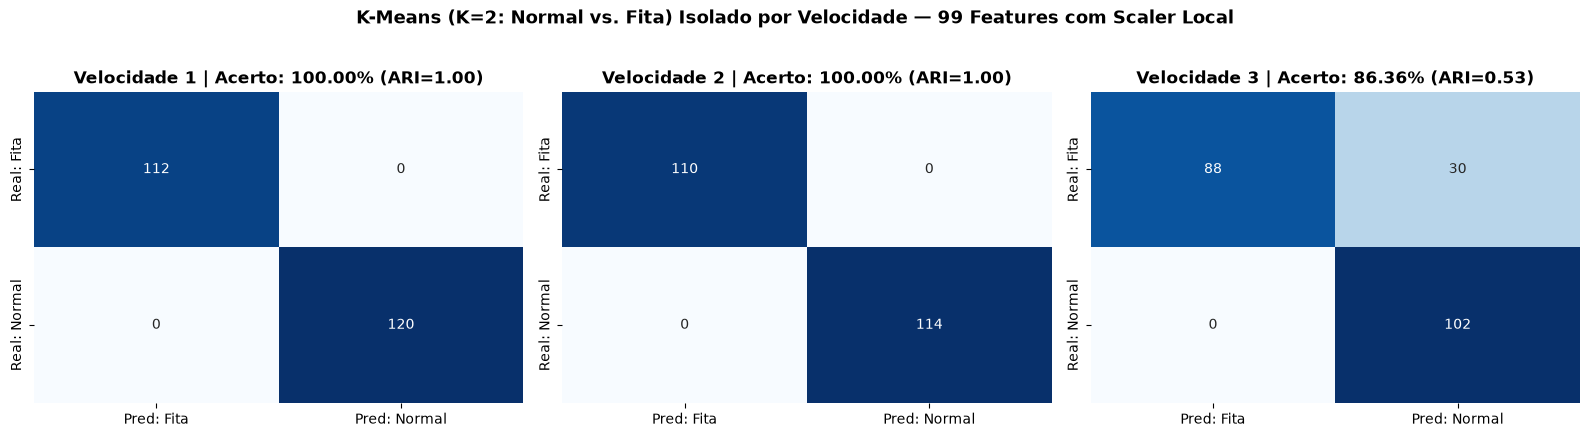

Acerto (%)                                 ARI            \
Matriz       99 Features PCA (95%) Somente Tempo 99 Features PCA (95%)   
Velocidade                                                               
Velocidade 1      100.00    100.00         100.0       1.000     1.000   
Velocidade 2      100.00    100.00         100.0       1.000     1.000   
Velocidade 3       86.36     86.36         100.0       0.527     0.527   

                            
Matriz       Somente Tempo  
Velocidade                  
Velocidade 1           1.0  
Velocidade 2           1.0  
Velocidade 3           1.0

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, adjusted_rand_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cols_tempo = [c for c in X_unificado.columns if not c.startswith('fft_')]
linhas_resumo = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
fig.suptitle("K-Means (K=2: Normal vs. Fita) Isolado por Velocidade — 99 Features com Scaler Local", 
             fontsize=13, fontweight='bold', y=1.03)

for i, vel in enumerate([1, 2, 3]):
    mask_vel = (gabarito_unificado['velocidade'] == vel).values
    X_vel = X_unificado.loc[mask_vel]
    y_vel = gabarito_unificado.loc[mask_vel, 'anomalia'].map({0: 'Normal', 1: 'Fita'})
    
    # Scaler ajustado APENAS dentro da velocidade atual
    X_vel_full = StandardScaler().fit_transform(X_vel)
    X_vel_tempo = StandardScaler().fit_transform(X_vel[cols_tempo])
    X_vel_pca = PCA(n_components=0.95, random_state=42).fit_transform(X_vel_full)
    
    for nome_mat, mat in [('Somente Tempo', X_vel_tempo), ('99 Features', X_vel_full), ('PCA (95%)', X_vel_pca)]:
        km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(mat)
        classes = np.sort(y_vel.unique())
        cm_t = contingency_matrix(y_vel, km.labels_)
        r_i, c_i = linear_sum_assignment(-cm_t)
        mapa = {c: classes[r] for r, c in zip(r_i, c_i)}
        y_p = np.array([mapa[l] for l in km.labels_])
        
        acc = accuracy_score(y_vel, y_p) * 100
        ari = adjusted_rand_score(y_vel, km.labels_)
        linhas_resumo.append({
            'Velocidade': f'Velocidade {vel}',
            'Matriz': nome_mat,
            'Acerto (%)': round(acc, 2),
            'ARI': round(ari, 3)
        })
        
        # Plotando a matriz para o cenário de 99 Features
        if nome_mat == '99 Features':
            cm_f = confusion_matrix(y_vel, y_p, labels=classes)
            sns.heatmap(cm_f, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                        xticklabels=[f'Pred: {c}' for c in classes],
                        yticklabels=[f'Real: {c}' for c in classes])
            axes[i].set_title(f"Velocidade {vel} | Acerto: {acc:.2f}% (ARI={ari:.2f})", fontweight='bold')

plt.tight_layout()
plt.show()

df_res_vel = pd.DataFrame(linhas_resumo).pivot(index='Velocidade', columns='Matriz', values=['Acerto (%)', 'ARI'])
display(df_res_vel)

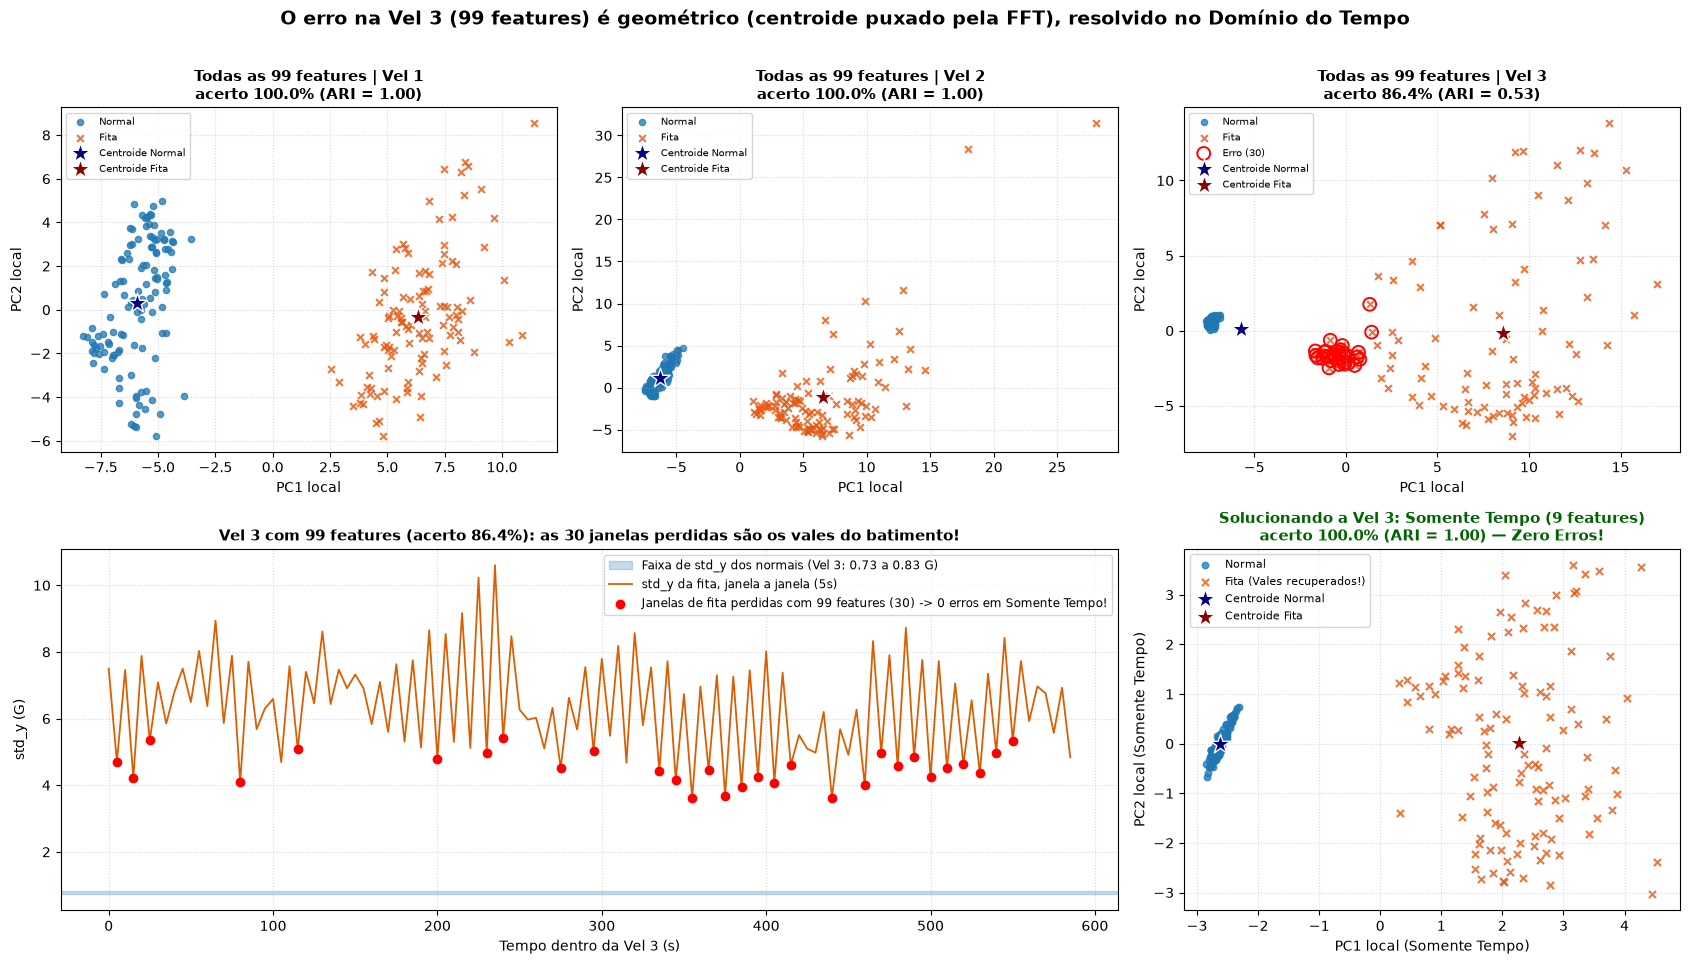

In [ ]:
# ==============================================================================
# PAINEL 2: DIAGNÓSTICO GEOMÉTRICO DO K=2 LOCAL E CORREÇÃO DOS 30 ERROS  DA VEL 3
# ==============================================================================
cols_tempo = [c for c in X_unificado.columns if not c.startswith('fft_')]

def rodar_k2_local(vel, usar_somente_tempo=False):
    mask = (gabarito_unificado['velocidade'] == vel).values
    X_sub = X_unificado.loc[mask, cols_tempo] if usar_somente_tempo else X_unificado.loc[mask]
    y_sub = gabarito_unificado.loc[mask, 'anomalia'].values  # 0=Normal, 1=Fita
    
    scaler = StandardScaler()
    X_esc = scaler.fit_transform(X_sub)
    
    km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_esc)
    cm_t = contingency_matrix(y_sub, km.labels_)
    r_i, c_i = linear_sum_assignment(-cm_t)
    mapa = {c: r for r, c in zip(r_i, c_i)}
    y_pred = np.array([mapa[l] for l in km.labels_])
    
    # Reordenando centroides para [0: Normal, 1: Fita]
    centroides_orig = np.zeros_like(km.cluster_centers_)
    for c_label, real_label in mapa.items():
        centroides_orig[real_label] = km.cluster_centers_[c_label]
        
    pca2 = PCA(n_components=2, random_state=42)
    pts_2d = pca2.fit_transform(X_esc)
    cent_2d = pca2.transform(centroides_orig)
    
    acc = (y_sub == y_pred).mean() * 100
    ari = adjusted_rand_score(y_sub, km.labels_)
    erros = (y_sub != y_pred)
    
    return {
        'pts_2d': pts_2d, 'cent_2d': cent_2d, 'y': y_sub, 'y_pred': y_pred,
        'erros': erros, 'acc': acc, 'ari': ari,
        'std_y': X_unificado.loc[mask, 'std_y'].values
    }

fig = plt.figure(figsize=(17, 9.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.05])

# --- LINHA DO TOPO: Vel 1 (99 feats), Vel 2 (99 feats), Vel 3 (99 feats vs Tempo) ---
res_v1_99 = rodar_k2_local(1, usar_somente_tempo=False)
res_v2_99 = rodar_k2_local(2, usar_somente_tempo=False)
res_v3_99 = rodar_k2_local(3, usar_somente_tempo=False)
res_v3_tm = rodar_k2_local(3, usar_somente_tempo=True)

configs_topo = [
    (gs[0, 0], res_v1_99, "Todas as 99 features | Vel 1"),
    (gs[0, 1], res_v2_99, "Todas as 99 features | Vel 2"),
    (gs[0, 2], res_v3_99, "Todas as 99 features | Vel 3")
]

for subplot_spec, res, titulo_base in configs_topo:
    ax = fig.add_subplot(subplot_spec)
    pts = res['pts_2d']
    y_real = res['y']
    erros = res['erros']
    c2d = res['cent_2d']
    
    # Plot Normal e Fita
    ax.scatter(pts[y_real == 0, 0], pts[y_real == 0, 1], c='#1f77b4', marker='o', s=20, alpha=0.75, label='Normal')
    ax.scatter(pts[y_real == 1, 0], pts[y_real == 1, 1], c='#e6550d', marker='x', s=24, alpha=0.8, label='Fita')
    
    # Destacando erros se houver
    if erros.any():
        ax.scatter(pts[erros, 0], pts[erros, 1], facecolors='none', edgecolors='red',
                   s=85, lw=1.4, label=f'Erro ({erros.sum()})')
        
    # Plotando os Centroides para mostrar por que o K-Means erra na Vel 3
    ax.scatter(c2d[0, 0], c2d[0, 1], c='navy', marker='*', s=220, edgecolor='white', zorder=10, label='Centroide Normal')
    ax.scatter(c2d[1, 0], c2d[1, 1], c='darkred', marker='*', s=220, edgecolor='white', zorder=10, label='Centroide Fita')
    
    ax.set_title(f"{titulo_base}\nacerto {res['acc']:.1f}% (ARI = {res['ari']:.2f})", fontweight='bold', fontsize=10.5)
    ax.set_xlabel("PC1 local")
    ax.set_ylabel("PC2 local")
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(fontsize=7.5, loc='upper left')

# --- LINHA DE BAIXO ESQUERDA (2 colunas): Série Temporal dos Vales na Vel 3 ---
ax_ts = fig.add_subplot(gs[1, :2])
sy_v3 = res_v3_99['std_y']
y_v3 = res_v3_99['y']
erros_v3 = res_v3_99['erros']

sy_norm = sy_v3[y_v3 == 0]
sy_fita = sy_v3[y_v3 == 1]
erros_fita = erros_v3[y_v3 == 1]

t_fita = np.arange(len(sy_fita)) * 5  # Janelas de 5 segundos

ax_ts.axhspan(sy_norm.min(), sy_norm.max(), color='#1f77b4', alpha=0.25,
              label=f'Faixa de std_y dos normais (Vel 3: {sy_norm.min():.2f} a {sy_norm.max():.2f} G)')
ax_ts.plot(t_fita, sy_fita, color='#d95f02', lw=1.3, label='std_y da fita, janela a janela (5s)')
ax_ts.scatter(t_fita[erros_fita], sy_fita[erros_fita], color='red', s=36, zorder=5,
              label=f'Janelas de fita perdidas com 99 features ({erros_fita.sum()}) -> 0 erros em Somente Tempo!')

ax_ts.set_title("Vel 3 com 99 features (acerto 86.4%): as 30 janelas perdidas são os vales do batimento!",
                fontweight='bold', fontsize=11)
ax_ts.set_xlabel("Tempo dentro da Vel 3 (s)")
ax_ts.set_ylabel("std_y (G)")
ax_ts.grid(True, linestyle=':', alpha=0.5)
ax_ts.legend(loc='upper right', fontsize=8.5)

# --- LINHA DE BAIXO DIREITA: Somente Tempo na Vel 3 (100% de Acerto) ---
ax_tm = fig.add_subplot(gs[1, 2])
pts_tm = res_v3_tm['pts_2d']
y_tm = res_v3_tm['y']
c2d_tm = res_v3_tm['cent_2d']

ax_tm.scatter(pts_tm[y_tm == 0, 0], pts_tm[y_tm == 0, 1], c='#1f77b4', marker='o', s=22, alpha=0.75, label='Normal')
ax_tm.scatter(pts_tm[y_tm == 1, 0], pts_tm[y_tm == 1, 1], c='#e6550d', marker='x', s=26, alpha=0.8, label='Fita (Vales recuperados!)')
ax_tm.scatter(c2d_tm[0, 0], c2d_tm[0, 1], c='navy', marker='*', s=220, edgecolor='white', zorder=10, label='Centroide Normal')
ax_tm.scatter(c2d_tm[1, 0], c2d_tm[1, 1], c='darkred', marker='*', s=220, edgecolor='white', zorder=10, label='Centroide Fita')

ax_tm.set_title(f"Solucionando a Vel 3: Somente Tempo (9 features)\nacerto {res_v3_tm['acc']:.1f}% (ARI = {res_v3_tm['ari']:.2f}) — Zero Erros!",
                fontweight='bold', fontsize=10.5, color='darkgreen')
ax_tm.set_xlabel("PC1 local (Somente Tempo)")
ax_tm.set_ylabel("PC2 local (Somente Tempo)")
ax_tm.grid(True, linestyle=':', alpha=0.5)
ax_tm.legend(fontsize=8, loc='upper left')

fig.suptitle("O erro na Vel 3 (99 features) é geométrico (centroide puxado pela FFT), resolvido no Domínio do Tempo",
             fontsize=13.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

=== SEPARAÇÃO TOTAL DAS 6 CLASSES (K=6) ===


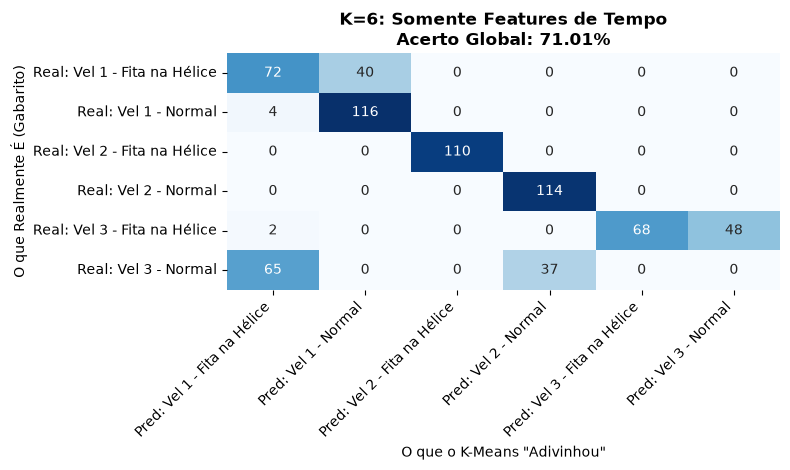

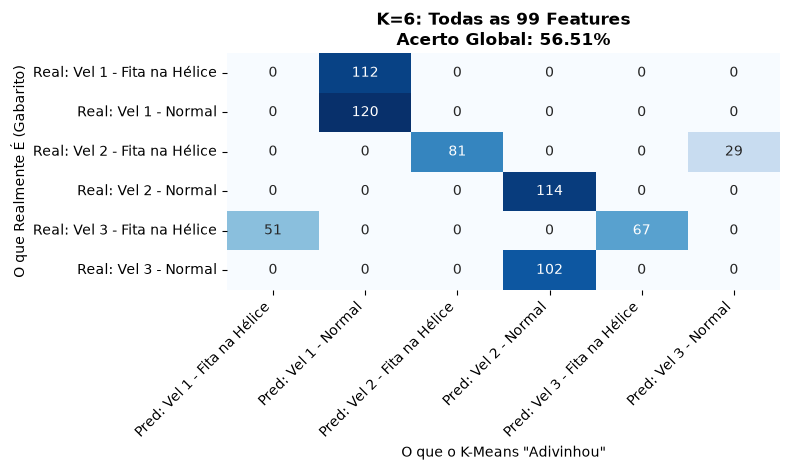

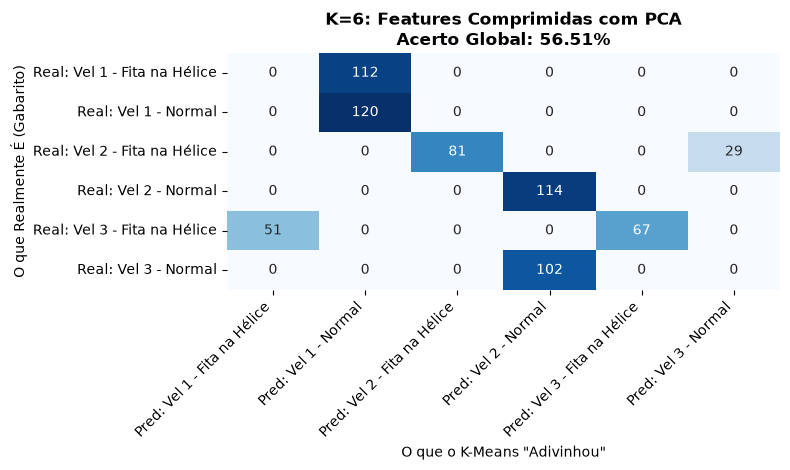

In [23]:
# ==============================================================================
# TESTE 2: K-MEANS MÚLTIPLO (AS 6 CLASSES FÍSICAS - K=6)
# ==============================================================================
# O gabarito agora é a coluna com as 6 classes completas ("Vel 1 Normal", "Vel 2 Fita", etc.)
y_multiclasse = gabarito_unificado['classe_completa']

print("=== SEPARAÇÃO TOTAL DAS 6 CLASSES (K=6) ===")

# Teste 2.1: Somente Tempo
acc_k6_tempo = avaliar_kmeans_velocidades(
    X_dados=X_scaled_tempo, 
    y_gabarito=y_multiclasse, 
    titulo="K=6: Somente Features de Tempo",
    k_clusters=6
)

# Teste 2.2: Todas as 99 Features
acc_k6_full = avaliar_kmeans_velocidades(
    X_dados=X_scaled_full, 
    y_gabarito=y_multiclasse, 
    titulo="K=6: Todas as 99 Features",
    k_clusters=6
)

# Teste 2.3: PCA
acc_k6_pca = avaliar_kmeans_velocidades(
    X_dados=X_scaled_pca, 
    y_gabarito=y_multiclasse, 
    titulo="K=6: Features Comprimidas com PCA",
    k_clusters=6
)

### 4.5. Diagnóstico dos Falsos Negativos no K=2 Unificado (Crosstab)
Para verificar quais regimes operacionais foram confundidos com o estado saudável no agrupamento binário global ($K=2$), cruzamos as predições do K-Means com as 6 classes reais do gabarito (`pd.crosstab`).

### 4.6. Detecção de Anomalia Condicionada ao Regime ($K=2$ por Velocidade)
Como já comprovamos que as 3 velocidades são separáveis com ~99% a 100% de acerto, avaliamos agora se o K-Means ($K=2$) consegue separar **Normal vs. Fita** dentro de cada velocidade isolada, reajustando o `StandardScaler` localmente para que a variância da Velocidade 1 não seja comprimida pela escala das Velocidades 2 e 3.

### 4.7. Sensibilidade à Escala Global: `log1p` e `RobustScaler` no Conjunto Unificado
Testamos se a compressão logarítmica das magnitudes (`log1p`, exceto curtose) combinada ou não com o `RobustScaler` (baseado em mediana e intervalo interquartil) reduz a dominância das Velocidades 2 e 3 e melhora a separação global para $K=2$ e $K=6$.

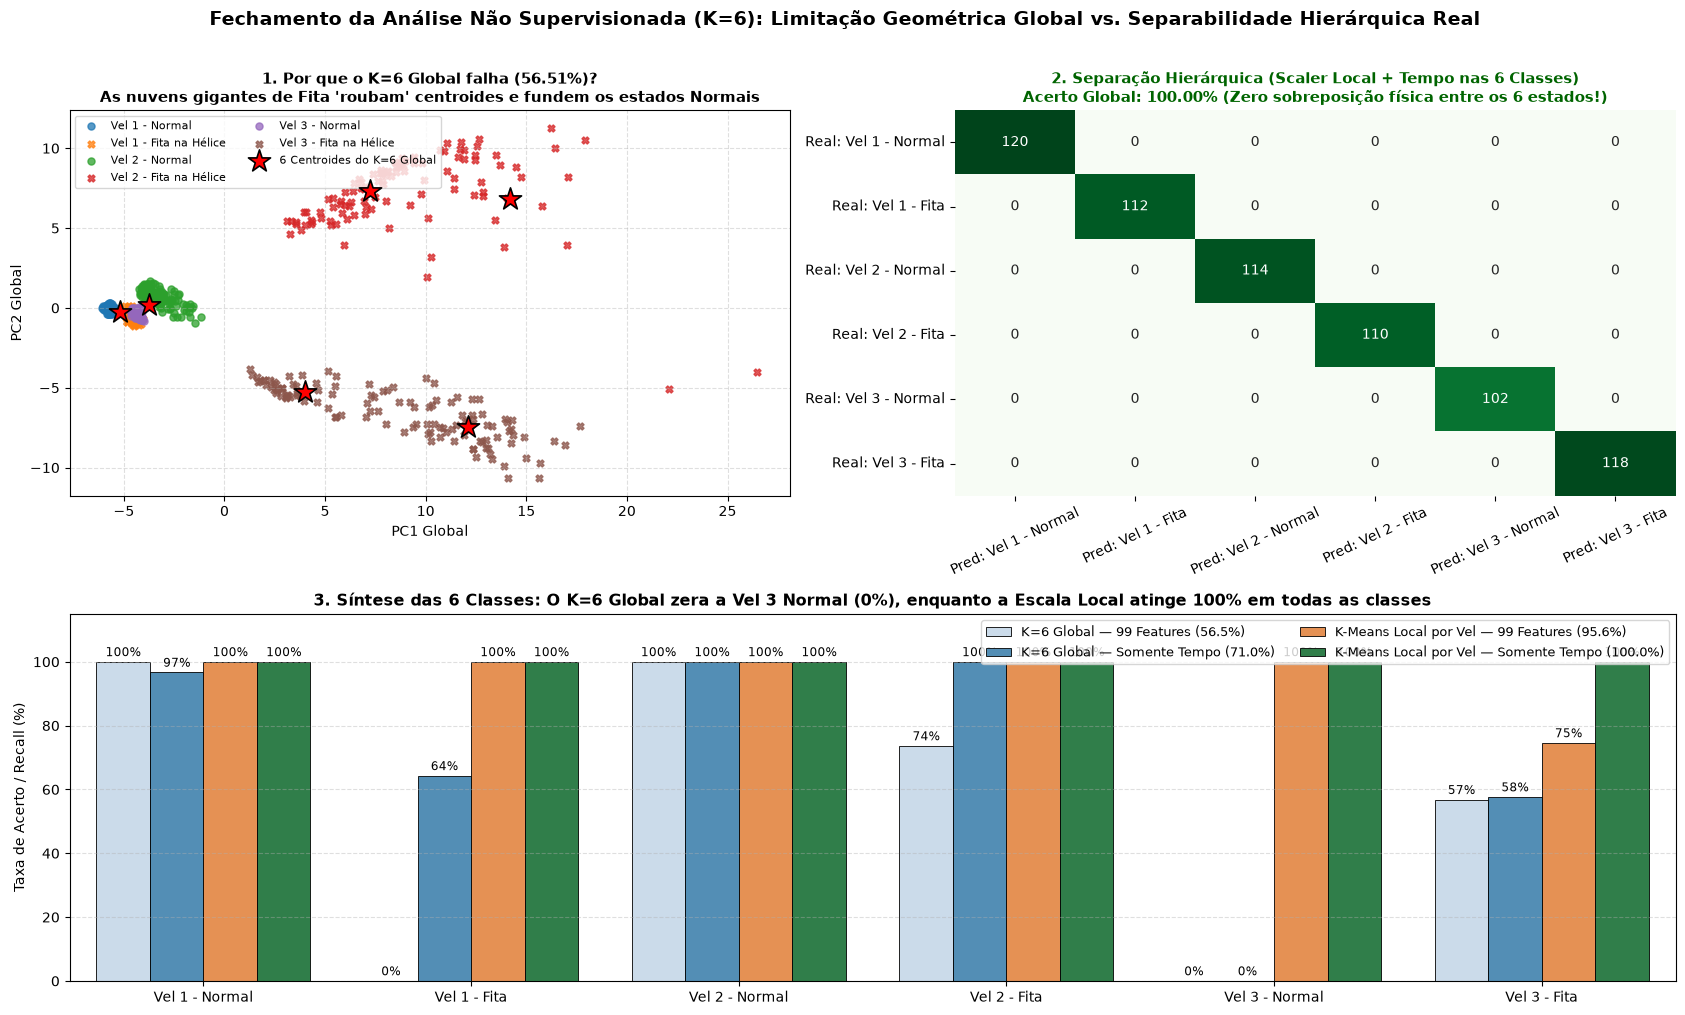

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment

# ==============================================================================
# 1. PREPARAÇÃO DOS CENÁRIOS PARA AS 6 CLASSES FÍSICAS
# ==============================================================================
cols_tempo = [c for c in X_unificado.columns if not c.startswith('fft_')]
y_6 = gabarito_unificado['classe_completa'].values
vels = gabarito_unificado['velocidade'].values

# Ordem lógica por velocidade (Normal seguido de Fita)
classes_unicas = np.unique(y_6)
ordem_logica = sorted(classes_unicas, key=lambda x: (int(x.split()[1]), 'Fita' in x))

def alinhar_predicoes(y_real, y_cluster, classes_ordenadas):
    cm_t = contingency_matrix(y_real, y_cluster)
    classes_padrao = np.sort(np.unique(y_real))
    r_i, c_i = linear_sum_assignment(-cm_t)
    mapa = {c: classes_padrao[r] for r, c in zip(r_i, c_i)}
    return np.array([mapa[l] for l in y_cluster])

# --- Cenário A: K=6 Global (99 Features) ---
X_glob_99 = StandardScaler().fit_transform(X_unificado)
km6_99 = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X_glob_99)
y_pred_glob99 = alinhar_predicoes(y_6, km6_99.labels_, ordem_logica)

# --- Cenário B: K=6 Global (Somente Tempo) ---
X_glob_tm = StandardScaler().fit_transform(X_unificado[cols_tempo])
km6_tm = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X_glob_tm)
y_pred_globtm = alinhar_predicoes(y_6, km6_tm.labels_, ordem_logica)

# --- Cenários C e D: K-Means Condicionado por Velocidade (K=2 Local em cada Vel) ---
y_pred_loc99 = np.empty_like(y_6)
y_pred_loctm = np.empty_like(y_6)

for v in [1, 2, 3]:
    m = (vels == v)
    y_sub = y_6[m]
    
    # Local 99 Features
    X_l99 = StandardScaler().fit_transform(X_unificado.loc[m])
    km_l99 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_l99)
    y_pred_loc99[m] = alinhar_predicoes(y_sub, km_l99.labels_, np.unique(y_sub))
    
    # Local Somente Tempo
    X_ltm = StandardScaler().fit_transform(X_unificado.loc[m, cols_tempo])
    km_ltm = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_ltm)
    y_pred_loctm[m] = alinhar_predicoes(y_sub, km_ltm.labels_, np.unique(y_sub))

# ==============================================================================
# 2. CONSTRUÇÃO DO PAINEL VISUAL (2x2)
# ==============================================================================
fig = plt.figure(figsize=(17, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1.1], height_ratios=[1.05, 1])

ax_pca = fig.add_subplot(gs[0, 0])
ax_cm  = fig.add_subplot(gs[0, 1])
ax_bar = fig.add_subplot(gs[1, :])

# --- SUBPLOT 1: O "Roubo de Centroides" no Espaço Global (PCA 2D) ---
pca2 = PCA(n_components=2, random_state=42)
pts_glob = pca2.fit_transform(X_glob_99)
cent_glob = pca2.transform(km6_99.cluster_centers_)

for cls in ordem_logica:
    m_c = (y_6 == cls)
    mk = 'o' if 'Normal' in cls else 'X'
    ax_pca.scatter(pts_glob[m_c, 0], pts_glob[m_c, 1], label=cls, s=26, alpha=0.75, marker=mk)

ax_pca.scatter(cent_glob[:, 0], cent_glob[:, 1], c='red', marker='*', s=280,
               edgecolor='black', lw=1.2, zorder=15, label='6 Centroides do K=6 Global')

ax_pca.set_title("1. Por que o K=6 Global falha (56.51%)?\nAs nuvens gigantes de Fita 'roubam' centroides e fundem os estados Normais",
                 fontweight='bold', fontsize=11)
ax_pca.set_xlabel("PC1 Global")
ax_pca.set_ylabel("PC2 Global")
ax_pca.grid(True, linestyle='--', alpha=0.4)
ax_pca.legend(fontsize=8, loc='upper left', ncol=2)

# --- SUBPLOT 2: Matriz 6x6 Condicionada por Velocidade (Somente Tempo = 100%) ---
cm_loc_tm = confusion_matrix(y_6, y_pred_loctm, labels=ordem_logica)
acc_loc_tm = accuracy_score(y_6, y_pred_loctm) * 100
rotulos_curtos = [c.replace(' na Hélice', '') for c in ordem_logica]

sns.heatmap(cm_loc_tm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax_cm,
            xticklabels=[f'Pred: {r}' for r in rotulos_curtos],
            yticklabels=[f'Real: {r}' for r in rotulos_curtos])
ax_cm.set_title(f"2. Separação Hierárquica (Scaler Local + Tempo nas 6 Classes)\nAcerto Global: {acc_loc_tm:.2f}% (Zero sobreposição física entre os 6 estados!)",
                fontweight='bold', fontsize=11, color='darkgreen')
ax_cm.tick_params(axis='x', rotation=25)
ax_cm.tick_params(axis='y', rotation=0)

# --- SUBPLOT 3: Comparativo de Recall por Classe nos 4 Cenários ---
cenarios_pred = {
    f'K=6 Global — 99 Features ({accuracy_score(y_6, y_pred_glob99)*100:.1f}%)': y_pred_glob99,
    f'K=6 Global — Somente Tempo ({accuracy_score(y_6, y_pred_globtm)*100:.1f}%)': y_pred_globtm,
    f'K-Means Local por Vel — 99 Features ({accuracy_score(y_6, y_pred_loc99)*100:.1f}%)': y_pred_loc99,
    f'K-Means Local por Vel — Somente Tempo ({acc_loc_tm:.1f}%)': y_pred_loctm
}

linhas_recall = []
for nome_cen, y_p in cenarios_pred.items():
    for cls, rot_curto in zip(ordem_logica, rotulos_curtos):
        m_c = (y_6 == cls)
        rec = (y_p[m_c] == cls).mean() * 100
        linhas_recall.append({'Classe Física': rot_curto, 'Cenário': nome_cen, 'Recall (%)': rec})

df_rec = pd.DataFrame(linhas_recall)
paleta_barras = ['#c6dbef', '#4292c6', '#fd8d3c', '#238b45']

sns.barplot(data=df_rec, x='Classe Física', y='Recall (%)', hue='Cenário',
            palette=paleta_barras, ax=ax_bar, edgecolor='black', linewidth=0.6)

for container in ax_bar.containers:
    ax_bar.bar_label(container, fmt='%.0f%%', fontsize=8.5, padding=2)

ax_bar.set_ylim(0, 115)
ax_bar.set_title("3. Síntese das 6 Classes: O K=6 Global zera a Vel 3 Normal (0%), enquanto a Escala Local atinge 100% em todas as classes",
                 fontweight='bold', fontsize=11.5)
ax_bar.set_xlabel("")
ax_bar.set_ylabel("Taxa de Acerto / Recall (%)")
ax_bar.grid(True, axis='y', linestyle='--', alpha=0.4)
ax_bar.legend(loc='upper right', fontsize=9, ncol=2)

fig.suptitle("Fechamento da Análise Não Supervisionada (K=6): Limitação Geométrica Global vs. Separabilidade Hierárquica Real",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()